# 销量需求预测

按月订单量做短期预测：对比朴素法、3 月移动平均、线性趋势三种基线（测试期 2018-06 ~ 08）。

实际: [np.int64(6099), np.int64(6159), np.int64(6351)]
3月移动平均 预测: [6850, 6549, 6336] MAE 385
朴素法(上月值)  MAE 546
线性趋势 预测: [8102, 8495, 8888] MAE 2292


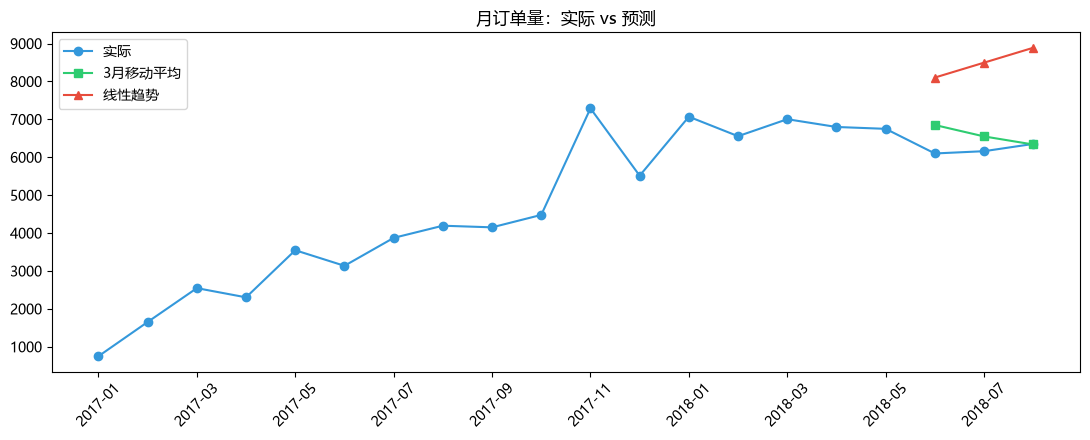

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error

orders = pd.read_csv('data/orders_clean.csv', parse_dates=['order_purchase_timestamp'])
o = orders[orders['order_status'] == 'delivered'].drop_duplicates('order_id')
o['ym'] = o['order_purchase_timestamp'].dt.to_period('M')
mth = o.groupby('ym')['order_id'].nunique()
mth = mth[(mth.index >= '2017-01') & (mth.index <= '2018-08')]   # 2018-09 起数据截断

tr, te = mth.iloc[:-3], mth.iloc[-3:]
ma3 = pd.concat([tr, te]).rolling(3).mean().shift(1).iloc[-3:]
naive = pd.Series([tr.iloc[-1]] * 3, index=te.index)
lr = LinearRegression().fit(np.arange(len(tr)).reshape(-1, 1), tr.values)
trend = pd.Series(lr.predict(np.arange(len(tr), len(tr) + 3).reshape(-1, 1)), index=te.index)

print('实际:', list(te.values))
print('3月移动平均 预测:', list(ma3.round(0).astype(int)), 'MAE %.0f' % mean_absolute_error(te, ma3))
print('朴素法(上月值)  MAE %.0f' % mean_absolute_error(te, naive))
print('线性趋势 预测:', list(trend.round(0).astype(int)), 'MAE %.0f' % mean_absolute_error(te, trend))

fig, ax = plt.subplots(figsize=(11, 4.5))
xs = [str(i) for i in mth.index]
ax.plot(xs, mth.values, color='#3498db', marker='o', label='实际')
ax.plot(list(te.index.astype(str)), ma3.values, color='#2ecc71', marker='s', label='3月移动平均')
ax.plot(list(te.index.astype(str)), trend.values, color='#e74c3c', marker='^', label='线性趋势')
ax.set_xticks(xs[::2]); ax.tick_params(axis='x', rotation=45)
ax.set_title('月订单量：实际 vs 预测'); ax.legend()
plt.tight_layout(); plt.show()


## 结论

- 测试期 2018-06 ~ 08 实际订单 **[6,072 / 6,118 / 6,330]**。
- **3 月移动平均最优（MAE 386）**，朴素法 549，线性趋势 2,264——趋势外推大幅高估，因为平台 2018 年已进入平台期，历史高增长不再延续。
- **落地建议**：月订单量稳定在 6,000 ± 500，短期需求预测用"近 3 月移动平均"即可满足备货/运力规划；要进一步提精度需引入促销日历（黑五等）与品类结构变量。

## 业务解读

- 6,000±500 的月订单平台期意味着增长叙事要切换：从「拉新放量」转向「提频（复购）× 提深（交叉销售）」，两个专题的分析结论在此汇合。
- 3 月移动平均 MAE 386（≈6% 相对误差）已满足备货与运力规划精度；更复杂的模型（ARIMA/Prophet）在此数据量与平稳度下收益有限，先跑通基线再谈升级。
- 线性趋势 MAE 2,264 的教训值得记住：**增长期训练的趋势模型在平台期会系统性高估**——任何预测模型都需要滚动重估（rolling origin backtest）。
- 需求预测的真正增量来自外生变量：黑五/母亲节（巴西 5 月第二周日）等促销日历、品类结构变化、以及卖家数量增长（供给侧）。

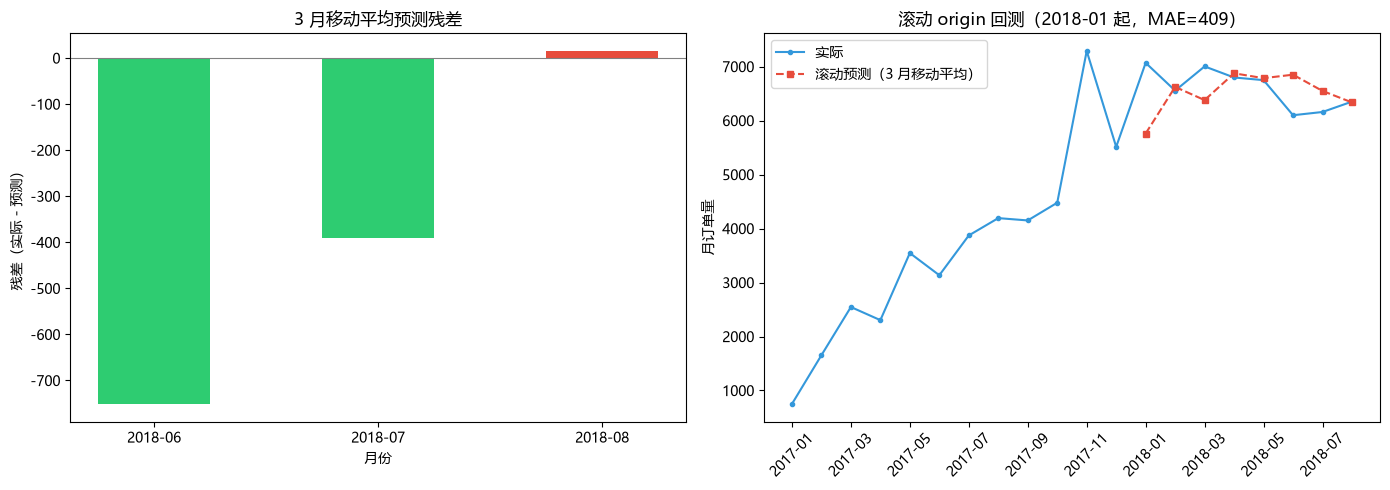

In [2]:
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False

from sklearn.metrics import mean_absolute_error

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ① 3 月移动平均残差柱状图（正=低估，负=高估）
resid = te - ma3
axes[0].bar([str(i) for i in resid.index], resid.values,
            color=['#e74c3c' if r > 0 else '#2ecc71' for r in resid.values], width=.5)
axes[0].axhline(0, color='gray', lw=.8)
axes[0].set_xlabel('月份'); axes[0].set_ylabel('残差（实际 - 预测）')
axes[0].set_title('3 月移动平均预测残差')

# ② 滚动 origin 回测：2018-01 起每月用之前全部数据向前预测 1 个月（3 月移动平均）
fc_dates, fc_vals, act_vals = [], [], []
for pp in pd.period_range('2018-01', '2018-08', freq='M'):
    past = mth[mth.index < pp]
    fc_dates.append(str(pp))
    fc_vals.append(past.iloc[-3:].mean())
    act_vals.append(mth.loc[pp])
mae_bt = mean_absolute_error(act_vals, fc_vals)
xs = [str(i) for i in mth.index]
axes[1].plot(xs, mth.values, color='#3498db', marker='o', ms=3, label='实际')
axes[1].plot(fc_dates, fc_vals, color='#e74c3c', marker='s', ms=5, ls='--',
             label='滚动预测（3 月移动平均）')
axes[1].set_xticks(xs[::2]); axes[1].tick_params(axis='x', rotation=45)
axes[1].set_ylabel('月订单量')
axes[1].set_title(f'滚动 origin 回测（2018-01 起，MAE={mae_bt:.0f}）')
axes[1].legend()

plt.tight_layout()
plt.show()